# 01 · Data acquisition, cohort design and metadata harmonisation

**Question addressed by the project.** Idiopathic pulmonary fibrosis (IPF) is a
progressive, fatal interstitial lung disease in which repetitive injury of the
alveolar epithelium is followed by aberrant repair, fibroblast activation and
extracellular-matrix (ECM) deposition. Single-cell RNA-seq (scRNA-seq) studies
in 2019-2020 described disease-emergent cell states - most notably
**KRT5⁻/KRT17⁺ "aberrant basaloid" epithelial cells**, **KRT8^hi transitional
alveolar cells**, **CTHRC1⁺/POSTN⁺ myofibroblasts** and **SPP1^hi macrophages**.

This project re-analyses two independent public cohorts from raw count matrices
with a modern, statistically rigorous workflow and asks:

1. Which cell types and states change in abundance in IPF (donor-level statistics)?
2. Which cell-type-specific transcriptional programmes change (pseudobulk DE)?
3. What transcriptional trajectory links AT2 cells to aberrant basaloid cells?
4. Which ligand-receptor circuits connect aberrant epithelium, fibroblasts and macrophages?
5. Do these findings **replicate in an independent cohort**?

| role | GEO | study | technology | donors |
|---|---|---|---|---|
| discovery | GSE135893 | Habermann *et al.* 2020, *Sci Adv* | 10x 5′ v1 | 10 control, 12 IPF, 10 other ILD |
| validation | GSE136831 | Adams *et al.* 2020, *Sci Adv* | 10x 3′ v2 | 28 control, 32 IPF, 18 COPD |

Files were downloaded with `workflow/scripts/download_data.py`, which verifies the
remote file size and records a SHA-256 checksum for each file.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from ipfatlas import io, qc
from ipfatlas.config import setup
from ipfatlas.plotting import CONDITION_COLORS, SITE_COLORS, figsize, panel_label, save_figure, set_style
from ipfatlas.utils import package_versions, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "01_data"
TAB = P.tables / "01_data"
package_versions()

,version
package,
python,3.11.18
numpy,2.2.6
scipy,1.16.3
pandas,2.3.3
anndata,0.12.19
scanpy,1.11.5
scvi-tools,1.4.2
torch,2.14.1+cu126
harmonypy,0.2.0


## 1. Provenance of the raw files

In [2]:
manifest = pd.read_csv(P.raw / "download_manifest.tsv", sep="\t")
manifest["MB"] = (manifest["bytes"] / 1e6).round(1)
manifest[["cohort", "accession", "file", "MB", "sha256", "retrieved"]]

,cohort,accession,file,MB,sha256,retrieved
0,discovery,GSE135893,GSE135893_IPF_metadata.csv.gz,3.4,5c67b3717375859aafc4463024847cf30d7af7bb9d5f4a...,2026-10-29T01:52:50
1,discovery,GSE135893,GSE135893_barcodes.tsv.gz,0.9,37a9a98a95d59bb4333c8181c14bb2b384701e6fda1c40...,2026-10-29T01:52:49
2,discovery,GSE135893,GSE135893_family.soft.gz,0.0,e7cab99cff19a915408b210b371a1d44d09b0c0379f0bb...,2026-10-29T01:52:51
3,discovery,GSE135893,GSE135893_genes.tsv.gz,0.1,7e8612e72f033ef214de101bb782ab1cb60b8c887be2d3...,2026-10-29T01:52:47
4,discovery,GSE135893,GSE135893_matrix.mtx.gz,1076.1,036987d06ed9625a71f5e5be0717c2598e914a6c9cad06...,2026-10-29T01:52:47
5,discovery,GSE135893,GSE135893_readme_for_ILD_annotated_fullsize.rd...,0.0,a7f878eb36efe4e549ae00538973da7c51de2cdbcf8550...,2026-10-29T01:52:51
6,validation,GSE136831,GSE136831_AllCells.GeneIDs.txt.gz,0.3,e43b3008945c87a6875d4fb1a99a791fdaefeeb3c5a72a...,2026-10-29T01:53:52
7,validation,GSE136831,GSE136831_AllCells.Samples.CellType.MetadataTa...,4.3,147bdd11d720ed30736a459ba62a3d8e2f3f9028a8430e...,2026-10-29T01:53:54
8,validation,GSE136831,GSE136831_AllCells.cellBarcodes.txt.gz,1.4,0efbb89de618a429e2db0399e25f9b2a0f7cd3b6d6ee9a...,2026-10-29T01:53:53
9,validation,GSE136831,GSE136831_RawCounts_Sparse.mtx.gz,2150.6,266133a964b5c45bf02394acaaff4ea4eb66096ec5a051...,2026-10-29T01:53:50


## 2. Discovery cohort (GSE135893)

The GEO matrix contains **all Cell Ranger-called barcodes** (220,213) of 43
libraries, i.e. *before* the authors' QC (≥1,000 genes, <25 % mitochondrial
reads), which retained 114,396 cells. Starting from this matrix lets us perform
QC ourselves rather than inherit the authors' choices. The authors' labels are
kept only for benchmarking.

In [3]:
adata = io.read_habermann(P.raw)
adata

02:14:02 | INFO | reading GSE135893_matrix.mtx.gz ...


02:14:17 | INFO | reading GSE135893_matrix.mtx.gz done in 14.9 s


02:14:31 | INFO | Habermann: 220,213 barcodes x 33,694 genes, 43 libraries, 30 donors


AnnData object with n_obs × n_vars = 220213 × 33694
    obs: 'library_id', 'donor_id', 'diagnosis', 'status', 'site', 'author_celltype', 'author_compartment', 'author_qc_pass', 'cohort', 'chemistry'
    var: 'gene_symbol'

In [4]:
lib = (adata.obs.groupby("library_id", observed=True)
       .agg(donor_id=("donor_id", "first"), diagnosis=("diagnosis", "first"), status=("status", "first"),
            site=("site", "first"), n_barcodes=("library_id", "size"),
            n_author_cells=("author_qc_pass", "sum"))
       .sort_values(["status", "diagnosis", "donor_id"]))
write_table(lib, TAB / "discovery_libraries")
lib

,donor_id,diagnosis,status,site,n_barcodes,n_author_cells
library_id,,,,,,
F01157,THD0001,Control,Control,DNA,3260,2218
F01174,THD0002,Control,Control,DNA,3253,2647
F01365,THD0005,Control,Control,DNA,1842,1191
F01366,THD0005,Control,Control,DNA,1813,1284
F01367,THD0005,Control,Control,DNA,1513,1019
HD65,VUHD65,Control,Control,Vanderbilt,4352,2552
HD66,VUHD66,Control,Control,Vanderbilt,4942,2802
HD67,VUHD67,Control,Control,Vanderbilt,12465,7612
HD68,VUHD68,Control,Control,Vanderbilt,10438,5815


In [5]:
donors = lib.groupby("donor_id").agg(diagnosis=("diagnosis", "first"), site=("site", "first"),
                                     n_libraries=("n_barcodes", "size"), n_barcodes=("n_barcodes", "sum"))
pd.crosstab(donors["diagnosis"], donors["site"], margins=True)

J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_54564\1565000487.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  donors = lib.groupby("donor_id").agg(diagnosis=("diagnosis", "first"), site=("site", "first"),


site,DNA,NTI,Vanderbilt,All
diagnosis,,,,
Control,3,0,7,10
ILD,0,1,0,1
IPF,0,5,7,12
NSIP,0,0,3,3
Sarcoidosis,0,1,1,2
cHP,0,0,2,2
All,3,7,20,30


**Design caveat — site is partly confounded with disease.** All donors from the
Donor Network of Arizona (DNA) are controls and all from NTI are fibrotic; only
Vanderbilt contributed both. A naive IPF-vs-control contrast therefore mixes
disease and site effects. We address this later with (i) a site-adjusted model,
(ii) a Vanderbilt-only sensitivity analysis and, most importantly, (iii)
replication in an independent cohort from a different centre.

Several donors contributed two libraries (e.g. upper and lower lobe, `VUILD59-1/-2`).
These are **technical/regional replicates of one biological replicate**: all
statistics below use the *donor* as the unit of replication.

## 3. Genetic sex inference
Sex is not recorded in GEO, but sex-linked expression is an important covariate.
Females express *XIST*; males express broadly transcribed chrY genes (*RPS4Y1*,
*DDX3Y*, *UTY*, *KDM5D*, *EIF1AY*...). Both are measured from the raw counts.

In [6]:
sex = qc.infer_sex(adata, donor_key="donor_id", layer=None)
sex = sex.join(donors[["diagnosis", "site"]])
write_table(sex, TAB / "discovery_inferred_sex")
sex.sort_values("diagnosis")

,total,XIST,chrY,XIST_per_10k,chrY_per_10k,inferred_sex,diagnosis,site
donor_id,,,,,,,,
THD0001,26718672.0,0.0,22117.0,0.000000,8.277732,male,Control,DNA
VUHD71,17678164.0,1.0,9877.0,0.000566,5.587119,male,Control,Vanderbilt
VUHD70,15709874.0,9.0,8291.0,0.005729,5.277573,male,Control,Vanderbilt
VUHD68,71081456.0,0.0,36301.0,0.000000,5.106957,male,Control,Vanderbilt
VUHD67,84102512.0,8059.0,0.0,0.958235,0.000000,female,Control,Vanderbilt
VUHD66,31997330.0,12.0,23390.0,0.003750,7.309985,male,Control,Vanderbilt
VUHD65,36923508.0,4.0,22580.0,0.001083,6.115345,male,Control,Vanderbilt
VUHD69,3578746.0,1577.0,0.0,4.406571,0.000000,female,Control,Vanderbilt
THD0002,23358808.0,3398.0,0.0,1.454697,0.000000,female,Control,DNA


J:\Portfolio_projects\Projects\scRNA\.cache\tmp\ipykernel_54564\1509809038.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dx, d in sex.groupby("diagnosis"):


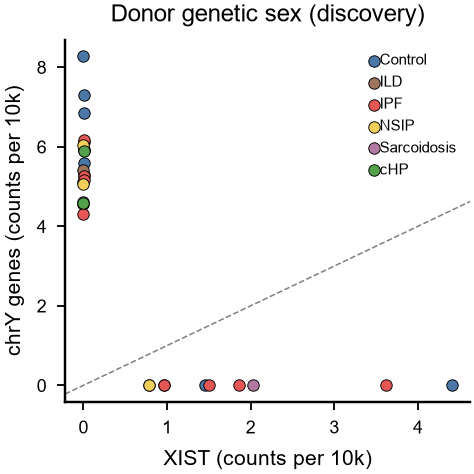

In [7]:
fig, ax = plt.subplots(figsize=figsize(60, 55))
for dx, d in sex.groupby("diagnosis"):
    ax.scatter(d["XIST_per_10k"], d["chrY_per_10k"], s=14, color=CONDITION_COLORS.get(dx, "grey"),
               edgecolor="black", lw=0.3, label=dx)
ax.axline((0, 0), slope=1, color="grey", lw=0.5, ls="--")
ax.set_xlabel("XIST (counts per 10k)")
ax.set_ylabel("chrY genes (counts per 10k)")
ax.set_title("Donor genetic sex (discovery)")
ax.legend(loc="upper right", fontsize=5, handletextpad=0.1)
save_figure(fig, "S1a_inferred_sex_discovery", FIG)
plt.show()

In [8]:
adata.obs["sex"] = adata.obs["donor_id"].map(sex["inferred_sex"]).astype("category")
pd.crosstab(sex["diagnosis"], sex["inferred_sex"])

inferred_sex,female,male
diagnosis,,
Control,3,7
ILD,0,1
IPF,5,7
NSIP,1,2
Sarcoidosis,1,1
cHP,0,2


## 4. Validation cohort (GSE136831) — metadata only
The 2 GB validation matrix is loaded in notebook 11; here we only describe its design.

In [9]:
vmeta = pd.read_csv(P.raw / "GSE136831" / "GSE136831_AllCells.Samples.CellType.MetadataTable.txt.gz", sep="\t")
vdon = vmeta.groupby("Subject_Identity").agg(diagnosis=("Disease_Identity", "first"),
                                              n_libraries=("Library_Identity", "nunique"),
                                              n_cells=("CellBarcode_Identity", "size"))
write_table(vdon, TAB / "validation_donors")
vdon["diagnosis"].value_counts()

diagnosis
IPF        32
Control    28
COPD       18
Name: count, dtype: int64

## 5. Figure: study design overview

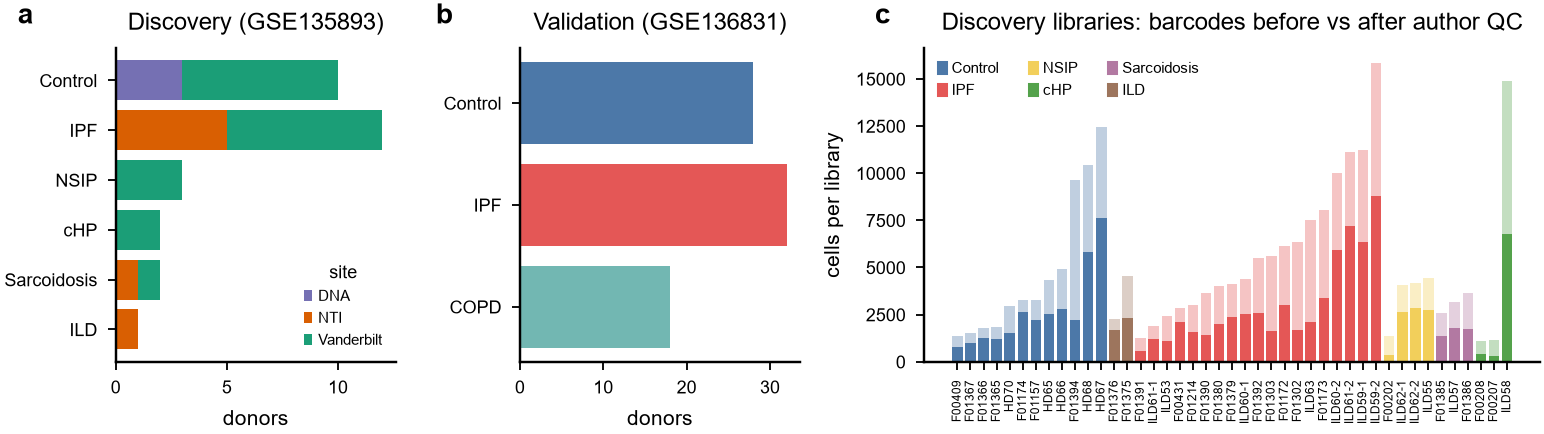

In [10]:
fig, axes = plt.subplots(1, 3, figsize=figsize(183, 55), gridspec_kw={"width_ratios": [1, 1, 2.2]})

ax = axes[0]
ct = pd.crosstab(donors["diagnosis"], donors["site"]).loc[["Control", "IPF", "NSIP", "cHP", "Sarcoidosis", "ILD"]]
ct.plot.barh(stacked=True, ax=ax, color=[SITE_COLORS[c] for c in ct.columns], width=0.8)
ax.invert_yaxis()
ax.set_xlabel("donors")
ax.set_ylabel("")
ax.set_title("Discovery (GSE135893)")
ax.legend(title="site", fontsize=5, title_fontsize=6)
panel_label(ax, "a", x=-0.35)

ax = axes[1]
vc = vdon["diagnosis"].value_counts().loc[["Control", "IPF", "COPD"]]
ax.barh(vc.index, vc.values, color=[CONDITION_COLORS[c] for c in vc.index])
ax.invert_yaxis()
ax.set_xlabel("donors")
ax.set_title("Validation (GSE136831)")
panel_label(ax, "b", x=-0.3)

ax = axes[2]
order = lib.sort_values(["diagnosis", "n_barcodes"]).index
colors = [CONDITION_COLORS.get(d, "grey") for d in lib.loc[order, "diagnosis"]]
ax.bar(range(len(order)), lib.loc[order, "n_barcodes"], color=colors, width=0.8, alpha=0.35, label="Cell Ranger barcodes")
ax.bar(range(len(order)), lib.loc[order, "n_author_cells"], color=colors, width=0.8, label="cells passing author QC")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=4)
ax.set_ylabel("cells per library")
ax.set_title("Discovery libraries: barcodes before vs after author QC")
handles = [plt.Rectangle((0, 0), 1, 1, color=CONDITION_COLORS[d]) for d in ["Control", "IPF", "NSIP", "cHP", "Sarcoidosis", "ILD"]]
ax.legend(handles, ["Control", "IPF", "NSIP", "cHP", "Sarcoidosis", "ILD"], ncol=3, fontsize=5)
panel_label(ax, "c", x=-0.08)
fig.tight_layout()
save_figure(fig, "Fig1_study_design_cohorts", FIG)
plt.show()

## 6. Save
Raw UMI counts are in `.X`. From notebook 02 on, they are kept unchanged in
`layers["counts"]` and every transformation writes to `.X` or new layers.

In [11]:
out = P.interim / "discovery_raw.h5ad"
adata.write_h5ad(out, compression="lzf")
print(out, f"{out.stat().st_size / 1e9:.2f} GB")

J:\Portfolio_projects\Projects\scRNA\data\interim\discovery_raw.h5ad 1.66 GB
